# Rapport final : Python pour la data-science 2A S1

Manon Bourguignat, Leila Héry, Franck Tran  
Chargé de TD : Lino Galiana

On pensera à lire le fichier README.md du repo qui contient notamment les informations sur les dépendances et les données.

### Sommaire

I. [Contexte](#i-contexte)  
&nbsp; &nbsp; &nbsp;1. [Présentation du sujet](#1-presentation-du-sujet)  
&nbsp; &nbsp; &nbsp;2. [Présentation de la base de données](#2-presentation-de-la-base-de-donnee-utilisee)

II. [Préparation des données](#ii-preparation-des-donnees)  
&nbsp; &nbsp; &nbsp;1. [Récupération des données](#1-recuperation-des-donnees)  
&nbsp; &nbsp; &nbsp;2. [Valeurs manquantes](#2-valeurs-manquantes)  
&nbsp; &nbsp; &nbsp;3. [Création de variables agrégées](#3-creation-de-variables-agregees)

III. [Visualisation](#iii-visualisation)  
&nbsp; &nbsp; &nbsp;1. [Statistiques descriptives](#1-statistiques-descriptives)  
&nbsp; &nbsp; &nbsp;2. [Analyse descriptive](#2-analyse-descriptive)  
&nbsp; &nbsp; &nbsp;3. [Approche bivariée et modélisation économétrique exploratoire](#3-approche-bivariee-et-modelisation-econometrique-exploratoire)

IV. [Conclusion](#iv-conclusion)

## I. Contexte

### 1. Presentation du sujet

La pandémie de Covid-19 a ravivé et intensifié une méfiance marquée envers les discours officiels au sein des démocraties européennes. Loin de constituer un simple manque d'information individuel, l'adhésion aux thèses complotistes reflète souvent une rupture démocratique et épistémique plus profonde vis-à-vis des institutions établies.

À partir des données de l'European Social Survey (ESS Round 10, 2020), notre étude vise à dépasser les seuls déterminants socio-économiques traditionnels (diplôme, revenu). Nous distinguons notamment la défiance envers le système politique de celle dirigée contre le consensus scientifique, tout en mesurant l'effet de la radicalité idéologique (éloignement du centre sur l'axe gauche-droite) et de l'ancrage territorial.

Notre travail s'articule ainsi autour de la problématique suivante :

> **« Dans quelle mesure l’adhésion aux théories du complot en Europe traduit-elle une défiance institutionnelle et scientifique plutôt qu’un clivage socio-économique traditionnel ? »**


### 2. Presentation de la base de donnee utilisee

L'European Social Service (ESS) est une enquête menée régulièrement dans plusieurs pays européens pour étudier les opinions, les valeurs et les comportements des populations. Chaque round (correspondant à une enquête réalisée une année donnée) comprend des variables communes à l'ensemble des rounds, ainsi que des variables propres aux thèmes étudiés.

Dans ce projet, on utilisera les données de l’ESS Round 10 (noté égament ESS10), édition 3.3, collectées en 2020 dont les thèmes sont la démocratie et les contacts sociaux numériques.

Tous les détails (références, licenses, accès) concernant les données se situent dans le fichier README.md.

## II. Preparation des donnees

Cette partie consiste en la récupération, l'exploration et le nettoyage des données. Cette partie se conclut sur la création d'un dataframe propre nommé `df_final` qui sera utilisé dans la partie III.

De nombreuses fonctions et variables utilisées sont regroupées dans des scripts python, dans le dossier "scripts" qu'on importe ici :

In [144]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
import textwrap
import statsmodels.formula.api as smf
import seaborn as sns

# On importe des fonctions définies dans preparation_data.py
from scripts.preparation_data import recuperer_donnees, select_colonne, suppr_colonne, renommer_colonne 

# On importe aussi les variables dans preparation_data.py
from scripts.preparation_data import dico_doi, colonnes_a_garder, nouveaux_noms, complot_cols, inst_cols, variable_expliqué, variables_explicatives, variable_finaux

# On importe des fonctions définies dans visualisation_data.py
from scripts.visualisation_data import moyenne_ponderee, ecart_type_pondere, quantile_pondere, creer_df_stats_continues, display_stats_desc

### 1. Recuperation des donnees

Le choix a été de récupérer les données de l'enquête de 2020 avec l'API dédiée pour deux raisons :
- Faciliter la reproductibilité : l'API est plus pratique que de chercher à récupérer les données sur le site
- L'infrastructure de recherche qui gère l'ESS recommande dans ses conditions d'utilisation (https://europeansocialsurvey.org/contact/disclaimer) de ne pas mettre les jeux de données de l’ESS à disposition sur des sites web externes.

Lorsqu’on exécute la fonction `recuperer_donnes` définie dans preparation_data.py, **il faut renseigner un "ESS User ID"**.

<details style="border: 1px solid #888; border-radius: 6px; padding: 8px;">
<summary style="font-weight: bold; cursor: pointer;">Où trouver mon ESS User ID ?</summary>

 Elle est disponible sur la page de l’API de l’ESS (https://ess.sikt.no/en/api) une fois connecté à un compte.
 
 On pourra également utiliser l'ESS User ID de Franck TRAN qu'il vous aura transmis par une autre voie. 
 
 Cet identifiant ne sert pas à s’authentifier, mais à suivre les statistiques d’utilisation des données. 

In [2]:
df_ess_2020 = recuperer_donnees(2020)
display(df_ess_2020.head(5))

,name,essround,edition,proddate,idno,cntry,dweight,pspwght,pweight,anweight,...,vinwe,inwde,jinws,jinwe,inwtm,mode,domain,prob,stratum,psu
0,ESS10e03_3,10,3.3,02.12.2025,10038,BE,0.882220,0.972276,0.718075,0.698167,...,2022-09-01 17:47:00,2022-09-01 17:47:00,2022-09-01 17:47:00,2022-09-01 17:47:00,36.0,1.0,1,0.000397,188,2596
1,ESS10e03_3,10,3.3,02.12.2025,10053,BE,1.047642,0.888635,0.718075,0.638107,...,2022-04-08 11:07:00,2022-04-08 11:10:00,2022-04-08 11:07:00,2022-04-08 11:10:00,54.0,2.0,2,0.000334,194,2206
2,ESS10e03_3,10,3.3,02.12.2025,10055,BE,1.087741,0.722811,0.718075,0.519033,...,2022-05-20 11:08:00,2022-05-20 11:10:00,2022-05-20 11:08:00,2022-05-20 11:10:00,77.0,1.0,2,0.000322,198,2114
3,ESS10e03_3,10,3.3,02.12.2025,10062,BE,0.909910,1.005565,0.718075,0.722072,...,2022-05-22 13:58:00,2022-05-22 13:59:00,2022-05-22 13:58:00,2022-05-22 13:59:00,55.0,1.0,1,0.000385,150,2645
4,ESS10e03_3,10,3.3,02.12.2025,10064,BE,0.918949,0.638705,0.718075,0.458639,...,2022-05-18 11:44:00,2022-05-18 11:45:00,2022-05-18 11:44:00,2022-05-18 11:45:00,55.0,1.0,1,0.000381,149,2313


On observe qu'il y a +37000 échantillons et +621 variables avec des noms pas très explicites comme `idno` pour désigner le numéro d’identification du répondant.

On conserve uniquement les colonnes susceptibles de contribuer à la réponse à la problématique avec `select_colonne` et la variable `colonnes_a_garder` (= liste contenant toutes les noms des colonnes à garder).

De même, `rename_colonne` et `nouveaux_noms` nous permettent de renommer :

In [145]:
df_ess_select = select_colonne(df_ess_2020, colonnes_a_garder)
df_ess_rename = renommer_colonne(df_ess_select, colonnes_a_garder, nouveaux_noms)
display(df_ess_rename.head(5))

,id,pays,poids_analyse,poids_design,poids_poststrat,complot_groupes_secrets,complot_science_politique,dissimulation_covid,mesures_sanitaires_controle,mesures_sanitaires_equilibre,...,activite_principale,chomage,milieu_residence,appartenance_religieuse,degre_religiosite,frequence_culte,frequence_priere,genre,age,annee_naissance
0,10038,BE,0.698167,0.882220,0.972276,4.0,3.0,4.0,7.0,2.0,...,NaN,0,4.0,1.0,7.0,3.0,1.0,2,16.0,2006.0
1,10053,BE,0.638107,1.047642,0.888635,3.0,3.0,3.0,4.0,6.0,...,NaN,1,4.0,2.0,4.0,7.0,7.0,2,24.0,1998.0
2,10055,BE,0.519033,1.087741,0.722811,4.0,5.0,5.0,7.0,5.0,...,NaN,0,4.0,2.0,0.0,7.0,7.0,1,58.0,1964.0
3,10062,BE,0.722072,0.909910,1.005565,NaN,NaN,5.0,9.0,5.0,...,NaN,0,1.0,1.0,5.0,7.0,6.0,1,35.0,1987.0
4,10064,BE,0.458639,0.918949,0.638705,5.0,5.0,5.0,9.0,5.0,...,NaN,0,2.0,2.0,1.0,7.0,7.0,1,61.0,1961.0


### 2. Valeurs manquantes

D'après la documentation, il y a de nombreuses formes possibles de non réponses (comme un `Refus`, `Ne sait pas` ou `Pas de réponse` qui sont codés par des valeurs particulières). Cependant, grâce à l'API, les données qu'on a récupéré ci-dessus sont déjà recodés en `np.nan`.

Regardons alors les variables ayant +5% de valeurs manquantes.

In [4]:
def show_df_val_manq(df):
    df_val_manquant = pd.DataFrame({
        "Nbr valeurs manquantes": df.isnull().sum(),
        "% valeurs manquantes": df.isnull().mean() * 100
    })

    df_val_manquant = df_val_manquant.sort_values(by="% valeurs manquantes", ascending=False).round(2)

    return df_val_manquant

# Ce dataframe des valeurs manquantes sera réutilisé par la suite
df_val_manq_avant = show_df_val_manq(df_ess_rename)

display(df_val_manq_avant[df_val_manq_avant["% valeurs manquantes"] >= 5])

,Nbr valeurs manquantes,% valeurs manquantes
refus_vaccin,37073,98.57
activite_principale,33940,90.24
degre_proximite_parti,23289,61.92
statut_vaccine,20679,54.98
decile_revenu,8239,21.91
confiance_science,7866,20.91
dissimulation_covid,5762,15.32
complot_groupes_secrets,5632,14.97
axe_gauche_droite,5297,14.08
complot_science_politique,5293,14.07


On supprime les variables `refus_vaccin`, `activite_principale`, `degre_proximite_parti`, `statut_vaccine` qui ont une part trop élevée de valeurs manquantes :

In [5]:
df_ess_suppr = suppr_colonne(df_ess_rename, 
    ["refus_vaccin", "activite_principale", "degre_proximite_parti", "statut_vaccine"])

print(df_ess_suppr.shape)

(37611, 35)


Quant aux autres variables ayant entre 10 % et 20 % de valeurs sont manquantes, on fait le choix de ne pas les supprimer. Lors de l'analyse descriptive, les valeurs manquantes seront exclues du calcul et des visualisations. 

En consultant la documentation méthodologique officielle de l'ESS Round 10 (*voir fichier README.md*), on remarque une absence totale de certaines valeurs dans certains pays, s'expliquant par les contraintes imposées par la crise sanitaire sur les modes de collecte.

<details style="border: 1px solid #888; border-radius: 6px; padding: 8px;">
<summary style="font-weight: bold; cursor: pointer;">Explication détaillée des valeurs manquantes à l'aide de la documentation</summary>

1. **Raccourcissement du questionnaire pour l'auto-passation (Self-Completion) :**  
   Plusieurs pays, dont le Monténégro (ME) et le Royaume-Uni (GB), ont dû abandonner le traditionnel entretien en face-à-face pour basculer en urgence vers un mode d'auto-administration (questionnaire web et papier par courrier). Pour limiter le fardeau cognitif et les taux d'abandon inhérents aux questionnaires sans enquêteur, l'ESS a drastiquement allégé le questionnaire, supprimant certains modules rotatifs secondaires dont les questions spécifiques sur la science (`trstsci`) ou les décisions secrètes.

2. **Divergences nationales d'implémentation du module Covid-19 :**  
   Pour la France (FR), le terrain d'enquête a été décalé et restructuré sous le format face-à-face assisté par ordinateur (CAPI), mais avec des arbitrages temporels stricts sur la durée de passation. L'équipe nationale de coordination a priorisé le tronc commun et le module démocratie, omettant l'extension facultative consacrée à la perception de la science et aux attitudes sanitaires alternatives.

Ces valeurs manquantes ne relèvent donc pas d'une non-réponse individuelle aléatoire (*Missing at Random*), mais d'un choix institutionnel de conception de l'enquête (*Structural Missings* / *Not Available*).

</details>

Pour notre analyse, cela implique de restreindre notre analyse aux pays ayant administré l'intégralité des questions. Regardons ainsi quels sont les pays où il y a beaucoup de valeurs manquantes :

In [6]:
# Soit les variables ayant entre 5% et 21% de valeurs manquantes
colonne_ayant_bcp_val_manq = ["decile_revenu", "confiance_science", "dissimulation_covid",
    "complot_groupes_secrets", "axe_gauche_droite", "complot_science_politique",
    "mesures_sanitaires_equilibre", "mesures_sanitaires_controle"]

df_par_pays = select_colonne(df_ess_suppr, colonne_ayant_bcp_val_manq)
df_par_pays = df_ess_suppr.groupby("pays").agg(lambda col: col.isnull().mean() * 100)

# Pour chaque variable e, regardons quels pays ont +20% de valeurs manquantes
for e in colonne_ayant_bcp_val_manq:
    df_temporaire = df_par_pays.sort_values(by=[e], ascending=False)
    display(df_temporaire.loc[df_temporaire[e] >= 20, [e]]
            .reset_index()
            .style.hide(axis="index")
            .format({e: "{:.2f}"}))


pays,decile_revenu
GR,46.09
IT,38.37
PT,34.28
IE,32.99
HR,30.53
CZ,30.45
SK,29.97
HU,26.93
MK,23.58


pays,confiance_science
EE,100.00
CZ,100.00
ME,100.00
FR,100.00


pays,dissimulation_covid
ME,100.00
FR,100.00
PT,23.01


pays,complot_groupes_secrets
ME,100.00
FR,100.00


pays,axe_gauche_droite
MK,38.42
ME,32.24
LT,26.94
IT,25.80
PT,20.78


pays,complot_science_politique
ME,100.00
FR,100.00


pays,mesures_sanitaires_equilibre
ME,100.00
FR,100.00


pays,mesures_sanitaires_controle
ME,100.00
FR,100.00


Pour `décile_revenu` et `axe_gauche_droite`, les valeurs manquantes se répartissent entre de nombreux pays.

Pour le reste des variables, l'examen détaillé des données révèle que le volume élevé de valeurs manquantes n'est pas homogène : il résulte principalement d'une absence totale de passation de ces variables dans certains pays (notamment 100 % de valeurs manquantes pour `confiance_science` en Estonie, Tchéquie, Monténégro et France). 

Afin de préserver la validité des indicateurs synthétiques qu'on créera et de garantir la comparabilité des résultats, il apparaît donc préférable d'exclure ces pays du champ de notre étude principale, quitte à réduire légèrement la taille de l'échantillon global.

In [19]:
df_ess_suppr_pays = df_ess_suppr[~df_ess_suppr["pays"].isin(["FR", "ME", "EE", "CZ"])]

print(df_ess_suppr_pays.shape)

(30338, 35)


Comparons avec les valeurs manquantes au début.

In [ ]:
df_val_manq_apres = show_df_val_manq(df_ess_suppr_pays)

# On joint les 2 dataframes des valeurs manquantes
df_val_manq_joint = df_val_manq_avant.merge(
    df_val_manq_apres,
    left_index=True,
    right_index=True,
    how="inner",
    suffixes=(" avant", " apres"),)

# On crée une nouvelle colonne
df_val_manq_joint["Variation en % des valeurs manquantes"] = (
    df_val_manq_joint["% valeurs manquantes apres"]
    - df_val_manq_joint["% valeurs manquantes avant"])

# On affiche ce qui nous intéresse
display(df_val_manq_joint
    .sort_values(by="% valeurs manquantes apres", ascending=False)
    .loc[
        df_val_manq_joint["% valeurs manquantes avant"] >= 5,
        ["% valeurs manquantes avant", "% valeurs manquantes apres", "Variation en % des valeurs manquantes"]
])

,% valeurs manquantes avant,% valeurs manquantes apres,Variation en % des valeurs manquantes
decile_revenu,21.91,23.38,1.47
axe_gauche_droite,14.08,14.00,-0.08
dissimulation_covid,15.32,7.67,-7.65
complot_groupes_secrets,14.97,7.18,-7.79
complot_science_politique,14.07,6.05,-8.02
mesures_sanitaires_equilibre,13.54,5.49,-8.05
confiance_science,20.91,1.95,-18.96
mesures_sanitaires_controle,10.44,1.94,-8.50


On observe ainsi que mise à part le décile de revenu, le taux de valeurs manquantes a bien diminué dans les autres variables.

### 3. Creation de variables agregees

Afin d'opérationnaliser notre problématique sans surcharger l'analyse, nous avons fait le choix de réduire drastiquement le nombre de dimensions en créant des indicateurs synthétiques dans un dataframe final nommé `df_final`. Au vu de la structure du jeu de données, nous restreignons notre analyse à un ensemble final de 13 variables clés : 3 variables "expliquées", 7 variables "explicatives" (mêlant indicateurs construits et variables brutes directement pertinentes) et 3 "variables d'informations sur l'individu".

1. **Variables expliquées (mesure de l'adhésion aux complots) :**
   * `score_complot` *(créée)* : indicateur continu (de 0 à 10) mesurant le niveau moyen d'adhésion aux récits complotistes (0 = n'adhère pas du tout, 10 = adhère complètement aux théories)

      <details style="border: 1px solid #888; border-radius: 6px; padding: 8px;">
         <summary style="font-weight: bold; cursor: pointer;">Explication détaillée</summary>
            Les variables "complot_groupes_secrets", "complot_science_politique", "dissimulation_covid" correspondent à une note de 1 (Très d'accord) à 5 (Pas du tout d'accord) concernant les affirmations : "Un petit groupe secret de personnes est responsable de toutes les grandes décisions de la politique mondiale.", "Des groupes de scientifiques manipulent, fabriquent ou suppriment des preuves afin de tromper le public.", "Le coronavirus est le résultat d'efforts délibérés et dissimulés de la part d'un gouvernement ou d'une organisation." 
            Score_complot est une moyenne ramené à une échelle de 0 à 10 de ces 3 variables (contenues dans la liste complot_cols dans preparation_data.py), puis on inverse l'échelle afin que 10 correspond à une adhésion totale aux complots.
      </details>
      <br>

   * `dissimulation_covid` *(modifiée)* : variable ordinale (1 à 5) mesurant la perception de rétention d'informations par les autorités lors de la crise sanitaire. 1 = pas d'accord, 5 = adhère complètement à l'affirmation "Le coronavirus est le résultat d'efforts délibérés et dissimulés de la part d'un gouvernement ou d'une organisation."


   * `adhesion_complot_forte` *(créée)* : indicatrice binaire (0 ou 1) identifiant les profils complotistes affirmés (accord $\ge 4/5$ sur au moins deux items), adaptée aux futures régressions logistiques.

      <details style="border: 1px solid #888; border-radius: 6px; padding: 8px;">
         <summary style="font-weight: bold; cursor: pointer;">Explication détaillée sur adhesion_complot_forte</summary>
            Elle vaut 1 si l'individu a déclaré être "(fortement) en accord" avec au moins deux sur les trois assertions décrites dans l'explication détaillée de score_complot
      </details>
   


In [127]:
df_clean = df_ess_suppr_pays.copy()

    # A) score synthétique continu de complotisme ramené sur une échelle de 0 à 10
df_clean["score_complot"] = 10 - (df_clean[complot_cols].mean(axis=1) - 1) * 2.5

    # B) Dissimulation_covid : on retourne de sorte que 5 = adhésion forte, 1 = pas d'adhésion
df_clean["dissimulation_covid"] = 6 - df_clean["dissimulation_covid"]

    # C) indicatrice d'adhésion forte 
    # (binaire : 1 si accord fort sur >= 2 items, 0 sinon, et np.nan dès qu'il y a une valeur manquante)
nb_accords = (df_clean[complot_cols] > 4).sum(axis=1)

df_clean["adhesion_complot_forte"] = np.where(
    df_clean[complot_cols].isna().any(axis=1),
    np.nan,
    (nb_accords >= 2).astype(int)
)

2. **Variables explicatives (déterminants politiques, culturels et structurels) :**
   * `confiance_institutions` *(créée)* : score continu (0 à 10) agrégeant la confiance dans le parlement, le personnel politique, les partis et la justice. 10 = confiance totale
   * `score_socioeco` *(créée)* : indicateur composite continu (borné de 0 à 1, inspiré de l'IDH) combinant le décile de revenu du ménage et le nombre d'années d'études.
   * `radicalite_politique` *(créée)* : distance absolue au centre (valeur = 5) sur l'axe gauche-droite pour capter l'effet des extrêmes.
   * `zone_rurale` *(créée)* : indicatrice binaire distinguant l'habitat rural/campagne du milieu urbain (1 si campagne/village, 0 si ville)
   * `confiance_science` *(brute)* : échelle continue (0 à 10) mesurant la confiance envers le consensus scientifique. 10 = confiance absolue
   * `degre_religiosite` *(brute)* : échelle continue (0 à 10) mesurant l'intensité de la foi personnelle. 10 = Très religieux
   * `age` *(brute)* : âge exact du répondant pour contrôler les effets de cohorte.

In [128]:
    # C) confiance institutionnelle moyenne (continue, 0 à 10 ou np.nan)
df_clean["confiance_institutions"] = df_clean[inst_cols].mean(axis=1)

    # D) score socio-économique composite normalisé (continu, 0 à 1 ou np.nan)
rev_norm = (df_clean["decile_revenu"] - 1) / 9.0
edu_norm = (df_clean["annees_etudes"] / 25.0).where(df_clean["annees_etudes"] <= 25)
df_clean["score_socioeco"] = (rev_norm + edu_norm) / 2.0

    # E) radicalité politique (continue, 0 à 5 ou np.nan)
df_clean["radicalite_politique"] = (df_clean["axe_gauche_droite"] - 5).abs()

    # F) zone rurale (0 ou 1 ou np.nan)
df_clean["zone_rurale"] = np.where(
    df_clean["milieu_residence"].isna(),
    np.nan,
    df_clean["milieu_residence"].isin([4, 5]).astype(int)
)

Ce resserrement méthodologique permet de disposer d'indicateurs continus robustes pour les régressions linéaires tout en évitant les problèmes de multicolinéarité liés à la multiplication de questions similaires.

3. **Variables d'informations :**
   * `id` *(brute)* : le numéro d’identification du répondant
   * `pays` *(brute)*
   * `poids_analyse` *(brute)* : coefficient attribué à chaque répondant qui indique combien de personnes il « représente » dans la population, pour que les statistiques reflètent la réalité du pays (ou de l’ensemble des pays) plutôt que seulement l’échantillon.

On prépare donc le dataframe `df_final` comme suit, où `variables_finales` est définie dans preparation_data comme étant la liste des 10 variables ci-dessus :

In [129]:
df_final = select_colonne(df_clean, ["id", "pays", "poids_analyse"] + variable_finaux)

display(df_final.head())
print(df_final.shape)

show_df_val_manq(df_final)

,id,pays,poids_analyse,score_complot,adhesion_complot_forte,dissimulation_covid,confiance_institutions,confiance_science,radicalite_politique,score_socioeco,degre_religiosite,zone_rurale,age
0,10038,BE,0.698167,3.333333,0.0,2.0,6.666667,8.0,2.0,NaN,7.0,1.0,16.0
1,10053,BE,0.638107,5.000000,0.0,3.0,4.500000,4.0,0.0,NaN,4.0,1.0,24.0
2,10055,BE,0.519033,0.833333,0.0,1.0,6.250000,9.0,0.0,0.693333,0.0,1.0,58.0
3,10062,BE,0.722072,0.000000,NaN,1.0,8.500000,8.0,0.0,0.573333,5.0,0.0,35.0
4,10064,BE,0.458639,0.000000,1.0,1.0,6.750000,9.0,1.0,0.657778,1.0,0.0,61.0


(30338, 13)


,Nbr valeurs manquantes,% valeurs manquantes
score_socioeco,7420,24.46
radicalite_politique,4247,14.00
adhesion_complot_forte,3896,12.84
dissimulation_covid,2326,7.67
score_complot,753,2.48
confiance_science,593,1.95
degre_religiosite,303,1.00
age,274,0.90
confiance_institutions,122,0.40
zone_rurale,48,0.16


## III. Visualisation 

Cette partie consiste en l'analyse et la visualsation de notre jeu de données `df_final` pour répondre à la problématique.

### 1. Statistiques descriptives

On peut à présent visualiser les différentes variables et afficher les statistiques descriptives pour ces dernières.

#### 1.1 - Variables expliquées 
Pour les variables continues, on retient la moyenne, la médiane et les premier et troisième quartile.

Pour l'unique variable binaire `adhesion_complot_forte`, on affiche simplement la part de chaque catégorie.
<br>

In [143]:
POIDS = "poids_analyse"

vars_expliquees_continues = ["score_complot", "dissimulation_covid"]

# --- Tableau des variables expliquées continues ---
tab_expliquees = creer_df_stats_continues(df_final, vars_expliquees_continues, POIDS)

display_stats_desc(tab_expliquees, titre = "Tableau 1 : statistiques descriptives des variables expliquées")


# --- Part de la population en adhésion forte (variable binaire) ---
sub = df_final[["adhesion_complot_forte", POIDS]].dropna()
part_forte = 100 * np.average(sub["adhesion_complot_forte"], weights=sub[POIDS])

display(Markdown("#### Part de la population en adhésion forte aux théories du complot"))
display(Markdown(f"**{part_forte:.1f} %** de la population présente une adhésion forte "
                 f"(accord ≥ 4/5 sur au moins deux items), "
                 f"estimation pondérée sur {len(sub):,} répondants.".replace(",", " ")))

,N valides,Moyenne (pond.),Écart-type (pond.),Q1 (pond.),Médiane (pond.),Q3 (pond.)
Score de complotisme (0-10),29585,4.10,2.42,2.50,4.17,5.83
Perception de dissimulation Covid (ordinale),28012,2.61,1.18,2.00,3.00,3.00


#### Part de la population en adhésion forte aux théories du complot

**12.9 %** de la population présente une adhésion forte (accord ≥ 4/5 sur au moins deux items)  estimation pondérée sur 26 442 répondants.

Une première analyse de ces résultats nous permet de voir que : 
* En moyenne, les enquêtés sont plutôt en désaccord avec les affirmations complotistes. En effet, la moyenne de **4.10/10** et une médiane de **4.17/10** dans le `score_de_complotisme`.
* Les enquêtés sont en moyenne plutôt en désaccord avec l'idée que le covid viendrait d'un gouvernement ou d'un organisme et cette moyenne qui vaut **2.61** est inférieur à la médiane qui vaut 3 : il y a donc + de personnes étant contre cette affirmation, ce qui tire la moyenne vers le bas. La médiane et le troisième quantile valent *3* qui est la valeur centrale de la variable qui varie entre 1 et 5. Ceci montre que de nombreuses personnes n'ont pas d'avis sur l'affirmation. 
* La variable de mesure de "l'adhésion forte" donne plus d'informations sur la part des gens adhérant fortement  puisque **12.9%** de notre échantillon semble présenter une adhésion forte à au moins deux des trois théories complotistes détaillées plus haut.

#### 1.2 - Variables explicatives 

On effectue à présent les mêmes analyses sur nos variables explicatives.

In [131]:
# --- Variables ---
vars_continues = ["confiance_institutions", "score_socioeco", "radicalite_politique",
    "confiance_science", "degre_religiosite", "age",]

tab_continues = creer_df_stats_continues(df_final, vars_continues, POIDS)

# Calcul du part de la population habitant une zone rurale (variable binaire)
sub = df_final[["zone_rurale", POIDS]].dropna()
part_rurale = 100 * np.average(sub["zone_rurale"], weights=sub[POIDS])

# On affiche
display_stats_desc(tab_continues, titre = "Tableau 2 : statistiques descriptives des variables continues")

display(Markdown("#### Part de la population habitant une zone rurale"))
display(Markdown(f"**{part_rurale:.1f} %** de la population vit en zone rurale (village ou campagne), "
                 f"estimation pondérée sur {len(sub):,} répondants.".replace(",", " ")))

,N valides,Moyenne (pond.),Écart-type (pond.),Q1 (pond.),Médiane (pond.),Q3 (pond.)
Confiance dans les institutions (0-10),30216,4.34,2.16,2.75,4.50,6.00
Score socio-économique (0-1),22918,0.52,0.19,0.37,0.52,0.67
Radicalité politique (0-5),26091,1.64,1.53,0.00,1.00,3.00
Confiance dans la science (0-10),29745,7.18,2.07,6.00,8.00,9.00
Degré de religiosité (0-10),30035,4.50,3.11,2.00,5.00,7.00
Âge (années),30064,48.96,19.15,33.00,49.00,64.00


#### Part de la population habitant une zone rurale

**36.7 %** de la population vit en zone rurale (village ou campagne)  estimation pondérée sur 30 290 répondants.

A partir de cette première visualisation on observe que  : 

* La moyenne de l'indicateur de radicalité politique de **1.64** et sa médiane de **1** indiquent une population enquêtée majoritairement modérée, et gloablement éloignée des extrêmes. C'est cohérent avec ce qu'indiquait la documentation des données ESS, puisque 33% de l'échantillon total enquêté se considérait comme parfaitement au centre (score de 5). 
Il convient cependant de considérer cet indicateur construit avec précaution, qui considère une "symétrie" dans la radicalité politique : en considérant **l'éloignement par rapport au centre**, et pas le **positionnement sur l'axe gauche droite**, on considère implicititement une radicalité similaire dans les positionnements vers la gauche ou vers la droite. 
* La confiance en les institutions est presque deux fois inférieure à la confiance dans la science, avec une dispersion similaire. **25%** des enquêtés ont un score de confiance dans les institutions supérieur à 6, contre **75%** pour le score de confiance dans la science. On observe ainsi une **défiance envers la vie politique** et ses représentants qui semble majoritairement partagée, quand au contraire le **consensus scientifique** semble globalement répandu, et les positions de défiance envers la science sont minoritaires. 
* Le degrés de religiosité avec une médiane de **5** indique répartition plus ou moins égale dans la population de la pratique religieuse; 

### 2. Analyse descriptive
#### 2.1 Représentation graphique des variables 

* **Variables individuelles**

On commence par une première visualisation des variables indviduelles principales : âge des individus enquêtés, profil socio-économique et dégrès de religiosité. 

**Age**

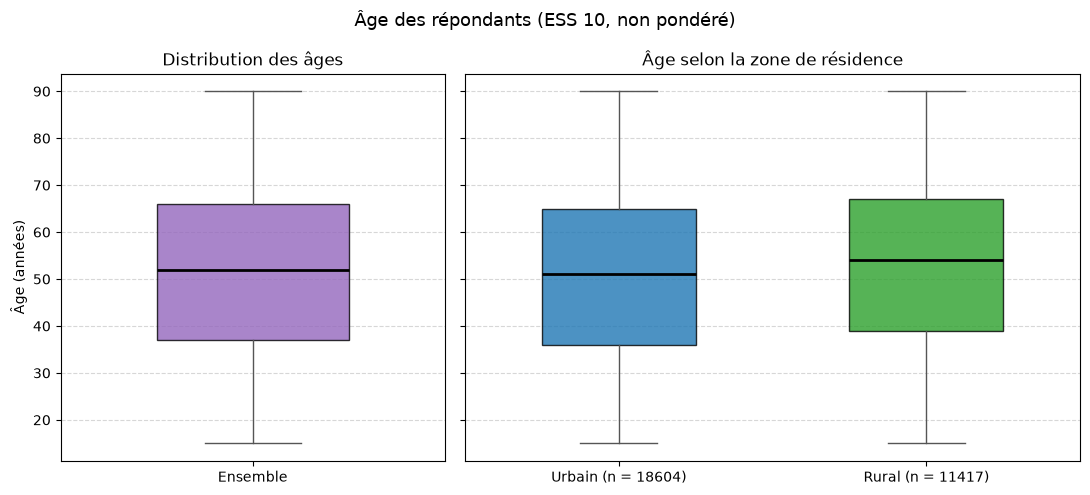

In [132]:
############# Boxplots : âge #############
d = df_final.dropna(subset=["age", "zone_rurale"])   # milieu manquant exclu (sinon compté comme urbain)

style = dict(patch_artist=True, widths=0.5,
             medianprops=dict(color="black", linewidth=2),
             whiskerprops=dict(color="#555555"), capprops=dict(color="#555555"))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})

# 1) Distribution des âges
ax = axes[0]
bp = ax.boxplot(df_final["age"].dropna(), **style)
bp["boxes"][0].set(facecolor="#9467bd", alpha=0.8)
ax.set_xticks([1])
ax.set_xticklabels(["Ensemble"])
ax.set_title("Distribution des âges")
ax.set_ylabel("Âge (années)")
ax.grid(axis="y", linestyle="--", alpha=0.5)

# 2) Âge selon la zone de résidence
ax = axes[1]
groupes = [d.loc[d["zone_rurale"] == k, "age"] for k in (0, 1)]
bp = ax.boxplot(groupes, **style)
for boite, couleur in zip(bp["boxes"], ["#1f77b4", "#2ca02c"]):
    boite.set(facecolor=couleur, alpha=0.8)
ax.set_xticks([1, 2])
ax.set_xticklabels([f"Urbain (n = {len(groupes[0])})", f"Rural (n = {len(groupes[1])})"])
ax.set_title("Âge selon la zone de résidence")
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.suptitle("Âge des répondants (ESS 10, non pondéré)", fontsize=13)
plt.tight_layout()
#fig.savefig(f"{DOSSIER_FIG}/boxplots_age.png", dpi=150)
plt.show()

On observe la répartition des âges d'abord dans l'absolu, puis selon si l'individu considéré habite une zone rurale ou non. La lecture du graphique donne  voir que l’âge médian est d’environ 52 ans avec une population concentrée entre 37 et 66 ans.
* Différences milieux urbains et ruraux : on observe que qes ruraux sont un peu plus âgés que les urbains avec une médiane est d’environ 54 ans contre 51, et leur boîte est décalée d’environ 3 ans vers le haut. 
<br>
Bien que l'écart soit modeste, ce décalage nous enjoint à prendre en compte le fait que les différences de complotisme entre zones rurales et urbaines peuvent être en partie amputées à un effet d'âge. 

* **Profil socio-économique**
<br>
On considère à présent notre variable du profil socio-économique, combinant revenu et niveau de diplôme. Une des défaillances principales de notre variables "profil socio-économique" est qu'elle ne permet pas de neutraliser les différences entre pays. En effet si le décile est calculé au niveau national (la population se répartir uniformément entre les dix déciles dans chaque pays), le niveau de diplôme est inégal entre les pays. On représente ainsi les bôites à moustache au niveau agrégé puis par pays.  


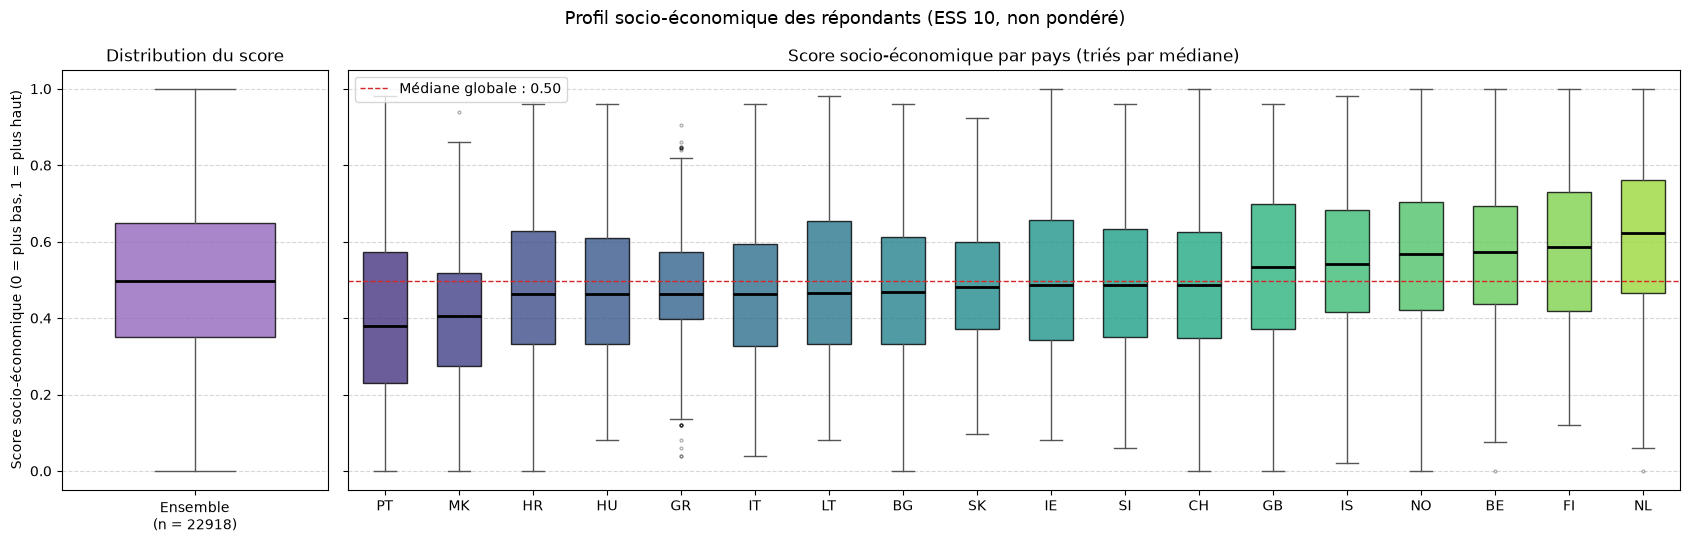

In [ ]:
############# Boxplots : score socio-économique #############
d = df_final.dropna(subset=["score_socioeco"])

style = dict(patch_artist=True, widths=0.6,
             medianprops=dict(color="black", linewidth=2),
             whiskerprops=dict(color="#555555"), capprops=dict(color="#555555"),
             flierprops=dict(marker="o", markersize=2, alpha=0.3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True, gridspec_kw={"width_ratios": [1, 5]})

# 1) Distribution globale
ax = axes[0]
bp = ax.boxplot(d["score_socioeco"], **style)
bp["boxes"][0].set(facecolor="#9467bd", alpha=0.8)
ax.set_xticks([1])
ax.set_xticklabels([f"Ensemble\n(n = {len(d)})"])
ax.set_title("Distribution du score")
ax.set_ylabel("Score socio-économique (0 = plus bas, 1 = plus haut)")
ax.grid(axis="y", linestyle="--", alpha=0.5)

# 2) Par pays (triés par médiane)
ax = axes[1]
ordre = d.groupby("pays")["score_socioeco"].median().sort_values().index
groupes = [d.loc[d["pays"] == p, "score_socioeco"] for p in ordre]
bp = ax.boxplot(groupes, **style)
couleurs = plt.cm.viridis(np.linspace(0.15, 0.85, len(ordre)))
for boite, c in zip(bp["boxes"], couleurs):
    boite.set(facecolor=c, alpha=0.8)
ax.axhline(d["score_socioeco"].median(), color="#d62728", linestyle="--", linewidth=1,
           label=f"Médiane globale : {d['score_socioeco'].median():.2f}")
ax.set_xticks(range(1, len(ordre) + 1))
ax.set_xticklabels(ordre)
ax.set_title("Score socio-économique par pays (triés par médiane)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper left")

fig.suptitle("Profil socio-économique des répondants (ESS 10, non pondéré)", fontsize=13)
plt.tight_layout()
#fig.savefig(f"{DOSSIER_FIG}/boxplots_socioeco.png", dpi=150)
plt.show()

L'observation des boîtes à moustache nous permet de constater cet effet pays dans la distribution des profils socio-économiques, en effet les écarts entre pays viennent presque uniquement de l’éducation et les différences de médianes s'expliquent donc par les années d’études, qui sont mesurées de façon absolue.
<br>
Les graphiques nous révèlent également que la position socio-économique varie surtout entre individus d’un même pays, plutôt qu'entre les pays entre eux : dans chaque pays, l’écart entre le quart inférieur et le quart supérieur (environ 0,25 à 0,35) dépasse l’écart entre les médianes extrêmes (0,25).
<br>

In [137]:
# Correspondance codes ESS -> noms de pays
noms_pays = {
    "AT": "Autriche", "BE": "Belgique", "BG": "Bulgarie", "CH": "Suisse",
    "CY": "Chypre", "CZ": "Tchéquie", "DE": "Allemagne", "DK": "Danemark",
    "EE": "Estonie", "ES": "Espagne", "FI": "Finlande", "FR": "France",
    "GB": "Royaume-Uni", "GR": "Grèce", "HR": "Croatie", "HU": "Hongrie",
    "IE": "Irlande", "IS": "Islande", "IT": "Italie", "LT": "Lituanie",
    "LU": "Luxembourg", "LV": "Lettonie", "ME": "Monténégro",
    "MK": "Macédoine du Nord", "NL": "Pays-Bas", "NO": "Norvège",
    "PL": "Pologne", "PT": "Portugal", "RO": "Roumanie", "RS": "Serbie",
    "SE": "Suède", "SI": "Slovénie", "SK": "Slovaquie",
}

* **Indicateurs de confiance**

<br>
Après cette première visualisation du profil des individus enquêtés, on en vient à s'intéresser à nos variables d'intérêt à savoir les indicateurs de confiance, puis l'adhésion aux théories complotistes.

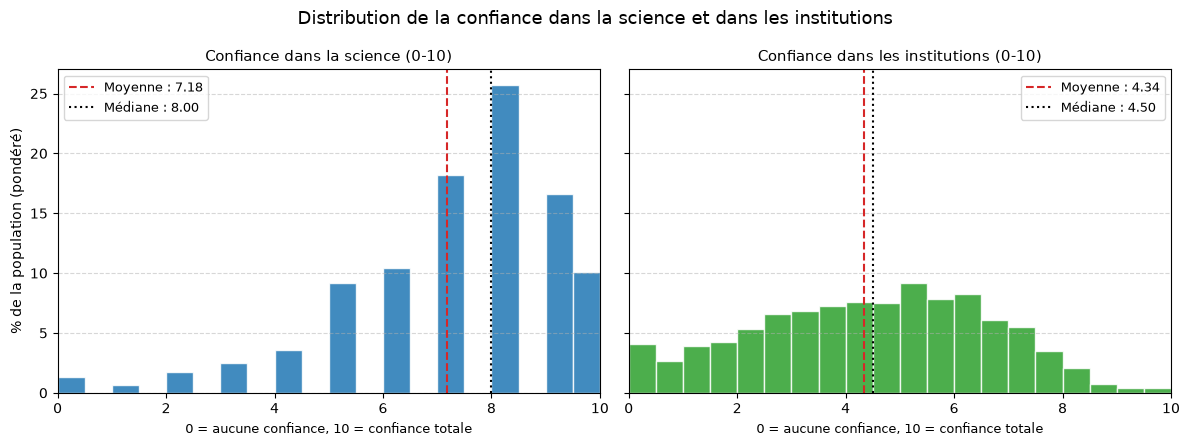

In [122]:
variables_hist = {
    "confiance_science": "Confiance dans la science (0-10)",
    "confiance_institutions": "Confiance dans les institutions (0-10)",
}
couleurs = ["#1f77b4", "#2ca02c"]
bins = np.linspace(0, 10, 21)  # mêmes classes (pas de 0,5) pour comparer les deux graphiques

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (var, titre), couleur in zip(axes, variables_hist.items(), couleurs):
    sub = df_final[[var, POIDS]].dropna()
    x, w = sub[var], sub[POIDS]

    # Histogramme pondéré, exprimé en % de la population
    ax.hist(x, bins=bins, weights=100 * w / w.sum(),
            color=couleur, edgecolor="white", alpha=0.85)

    # Moyenne et médiane pondérées
    moy = moyenne_ponderee(x, w)
    med = quantile_pondere(x, w, 0.5)
    ax.axvline(moy, color="#d62728", linestyle="--", linewidth=1.5, label=f"Moyenne : {moy:.2f}")
    ax.axvline(med, color="black", linestyle=":", linewidth=1.5, label=f"Médiane : {med:.2f}")

    ax.set_title(titre, fontsize=11)
    ax.set_xlabel("0 = aucune confiance, 10 = confiance totale", fontsize=9)
    ax.set_xlim(0, 10)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend(fontsize=9)

axes[0].set_ylabel("% de la population (pondéré)")
fig.suptitle("Distribution de la confiance dans la science et dans les institutions", fontsize=13)
plt.tight_layout()
plt.show()

* **Confiance dans la Science** : On observe une distribution très asymétrique à gauche, avec une masse importante entre 7 et 10 et une queue de faible confiance (0 à 4) minoritaire. On constate à nouveau sur cet histogramme qu'une part très minoritaire de la population déclare un indice de confiance entre 0 et 3, tandis que plus de la moitié de la population déclare une confiance supérieure à 8. 
* **Confiance dans les institutions** : le graphique nous permet d'observer une dispersion beaucoup plus élevée pour cet indice : la distribution en forme de cloche aplatie, rélève la présence d'une défiance marquée (environ 4 % à 0) et une certaine confiance, mais très peu de confiance élevée (presque rien au-dessus de 8).
<br>
<br>
On constate ici une vraie hétérogénéité absente de la variable de <i>confiance dans la science</i>, hétérogénéité qui suggère de vraies différences entre individus, mais aussi entre pays, puisque les données sont agrégées.
<br>
<br>
Pour identifier les facteurs de cette dispersion, et voir si celle-ci se situe davantage au niveau micro (profil socio-économique ou âge des individus) ou macro, en considérant les pays dans leur ensemble, on divise la population enquêtée en sous-groupe et on représente l'indice moyen de confiance dans les institutions en fonction de l'âge, du profil socio-économique puis du pays.

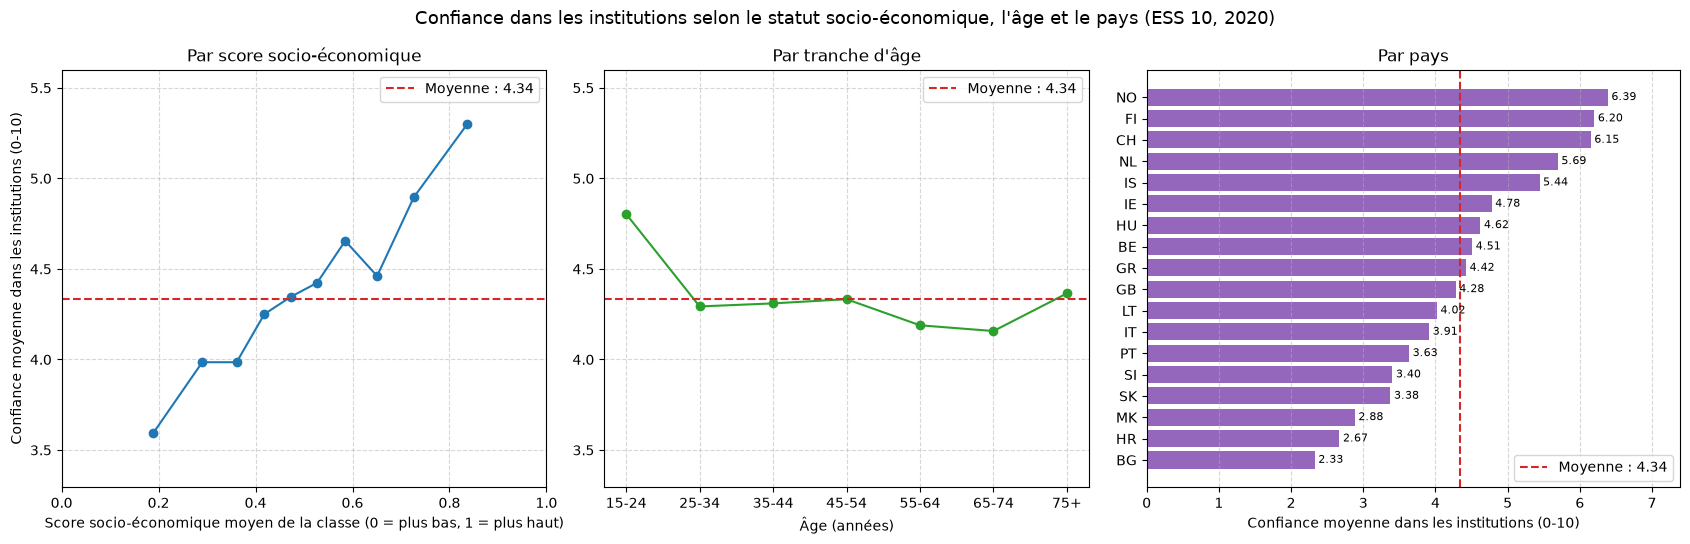

In [138]:
POIDS = "poids_analyse"
cols = ["confiance_institutions", "score_socioeco", "age", "pays", POIDS]
d = df_final[cols].copy()

def moy_pond(g, var="confiance_institutions"):
    g = g[[var, POIDS]].dropna()
    return np.average(g[var], weights=g[POIDS]) if len(g) else np.nan

moy_globale = moy_pond(d)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.1]})

# 1) Par score socio-économique (10 classes de taille égale)
ax = axes[0]
NB_CLASSES = 10
ds = d.dropna(subset=["score_socioeco"]).copy()
ds["classe_score"] = pd.qcut(ds["score_socioeco"], q=NB_CLASSES, labels=False, duplicates="drop")
par_score = ds.groupby("classe_score").apply(
    lambda g: pd.Series({"score_moy": moy_pond(g, "score_socioeco"),
                         "confiance": moy_pond(g)})
)
ax.plot(par_score["score_moy"], par_score["confiance"], marker="o", color="#1f77b4")
ax.axhline(moy_globale, color="#d62728", linestyle="--", label=f"Moyenne : {moy_globale:.2f}")
ax.set_title("Par score socio-économique")
ax.set_xlabel("Score socio-économique moyen de la classe (0 = plus bas, 1 = plus haut)")
ax.set_ylabel("Confiance moyenne dans les institutions (0-10)")
ax.set_xlim(0, 1)
ax.grid(linestyle="--", alpha=0.5)
ax.legend()

# 2) Par tranche d'âge
ax = axes[1]
bornes = [14, 24, 34, 44, 54, 64, 74, 120]
etiquettes = ["15-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75+"]
d["tranche_age"] = pd.cut(d["age"], bins=bornes, labels=etiquettes)
par_age = d.dropna(subset=["tranche_age"]).groupby("tranche_age", observed=True).apply(moy_pond)
ax.plot(par_age.index.astype(str), par_age.values, marker="o", color="#2ca02c")
ax.axhline(moy_globale, color="#d62728", linestyle="--", label=f"Moyenne : {moy_globale:.2f}")
ax.set_title("Par tranche d'âge")
ax.set_xlabel("Âge (années)")
ax.grid(linestyle="--", alpha=0.5)
ax.legend()

# 3) Par pays
ax = axes[2]
par_pays = d.groupby("pays").apply(moy_pond).sort_values()
barres = ax.barh(par_pays.index, par_pays.values, color="#9467bd")
ax.axvline(moy_globale, color="#d62728", linestyle="--", label=f"Moyenne : {moy_globale:.2f}")
for b, v in zip(barres, par_pays.values):
    ax.text(v + 0.05, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=8)
ax.set_title("Par pays")
ax.set_xlabel("Confiance moyenne dans les institutions (0-10)")
ax.set_xlim(0, par_pays.max() + 1)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")

# Mêmes bornes verticales pour les deux courbes
ymin = min(par_score["confiance"].min(), par_age.min()) - 0.3
ymax = max(par_score["confiance"].max(), par_age.max()) + 0.3
axes[0].set_ylim(ymin, ymax)
axes[1].set_ylim(ymin, ymax)

fig.suptitle("Confiance dans les institutions selon le statut socio-économique, l'âge et le pays (ESS 10, 2020)", fontsize=13)
plt.tight_layout()
plt.show()

* **Niveau de confiance selon le pays** : comme on l'observe sur le graphique les pays scandinaves, les Pays-bas et la Suisse sont ceux enregistrant la confiance moyenne dans les institutions la plus élevée. Au contraire les pays post-communistes et d'ex Yougoslavie (Hongrie, Lituanie, Bulgarie, Slovénie, Slovaquie Macédoine du Nord) sont en bas de la distribution, avec trois pays enregistrant des niveaux inférieurs à 3 (Hongrie, Macédoine et Bulgarie). Bien que nécéssitant une analyse plus poussée sur les facteurs de défiance institutionnelle en fonction de la qualité et de l'ancienneté des institutions, et de la présence potentielle de corruption ces résultats semblent cohérents. 
* **Selon l'âge** : Mise à part les groupe 15-24, 55-64 et 65-74 qui se distinguent légèrement, l'âge semble avoir un effet négligeable sur la confiance dans les institutions bien que la courbe ne soit pas parfaitement plate. 
* **Profil socio-économique** : On observe sur le graphique une relation monotone (bien que non linéaire) entre profil socio-économique (moyenne entre décile de revenu et années d'éducation) et confiance dans les institutions, avec un écart d'1.7 points entre le haut et le bas de la distribution. La relation est non linéaire puisque le niveau de confiance varie plus vite dans les deux extrêmes de la distribution, tandis que le profil socio-économique a un impact plus modéré au milieu de la distribution. 
<br>
Cependant, l'analyse du profil socio-économique seule ne permet pas de mesurer quelle part du gain est liée à l'éducation ou à l'absorption de l'effet pays. En effet si le décile de revenu est calculé par rapport aux habitants d'un même pays, les années d'éducation elles ne prennent pas en compte les différences de niveaux d'éducation entre pays.


**Indicateurs de complotisme** 


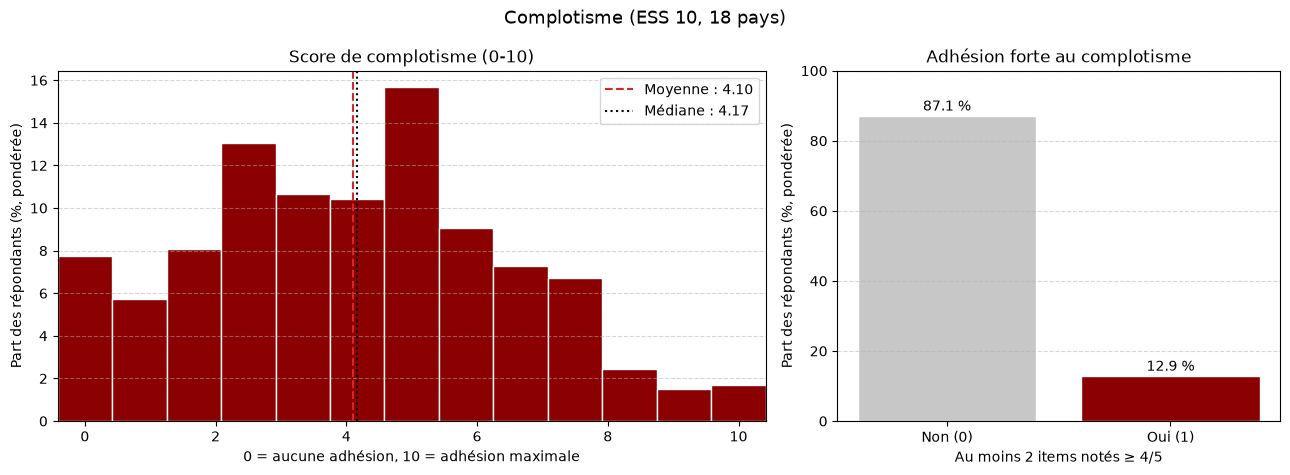

In [139]:
############# Histogrammes : complotisme #############
dc = df_final

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

# 1) Score de complotisme (continu)
ax = axes[0]
d = dc.dropna(subset=["score_complot", POIDS])
x, w = d["score_complot"].to_numpy(float), d[POIDS].to_numpy(float)
pas = 2.5 / len(complot_cols)                      # écart entre deux valeurs possibles du score
bins = np.arange(-pas / 2, 10 + pas, pas)          # une barre centrée sur chaque valeur possible
ax.hist(x, bins=bins, weights=100 * w / w.sum(), color="darkred", edgecolor="white")
def quant_pond(x, w, q):
    i = np.argsort(x)
    x, w = x[i], w[i]
    c = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, c, x)
m, med = np.average(x, weights=w), quant_pond(x, w, 0.5)
ax.axvline(m, color="#d62728", linestyle="--", label=f"Moyenne : {m:.2f}")
ax.axvline(med, color="black", linestyle=":", label=f"Médiane : {med:.2f}")
ax.set_xlim(-pas / 2, 10 + pas / 2)
ax.set_title("Score de complotisme (0-10)")
ax.set_xlabel("0 = aucune adhésion, 10 = adhésion maximale")
ax.set_ylabel("Part des répondants (%, pondérée)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

# 2) Adhésion forte (binaire)
ax = axes[1]
d = dc.dropna(subset=["adhesion_complot_forte", POIDS])
w = d[POIDS]
parts = (w.groupby(d["adhesion_complot_forte"]).sum() / w.sum() * 100).reindex([0, 1], fill_value=0)
barres = ax.bar(["Non (0)", "Oui (1)"], parts.values, color=["#c7c7c7", "darkred"], edgecolor="white")
for b, v in zip(barres, parts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f} %", ha="center")
ax.set_ylim(0, 100)
ax.set_title("Adhésion forte au complotisme")
ax.set_xlabel("Au moins 2 items notés ≥ 4/5")
ax.set_ylabel("Part des répondants (%, pondérée)")
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.suptitle(f"Complotisme (ESS 10, {dc['pays'].nunique()} pays)", fontsize=13)
plt.tight_layout()
#fig.savefig(f"{DOSSIER_FIG}/histogrammes_complot.png", dpi=150)
plt.show()

On observe un score de complotisme centré au milieu de l'échelle avec un pic à 5 correspondant aux réponses neutres. L'hypothèse d'une défiance diffuse, qui traduirait d'avantage une tendance à acquiscer plutôt qu'un complotisme strict est toutefois à nuancer puisque la variable mesurant l'adhésion forte indique que près de la moitié des répondants (**45,3 %**) sont en adhésion forte avec au moins deux théories complotistes. 
<br>
La forte dispersion du niveau de confiance en les institutions selon les pays nous amène à vouloir tester la répartition de ces score de complotisme selon les pays. 

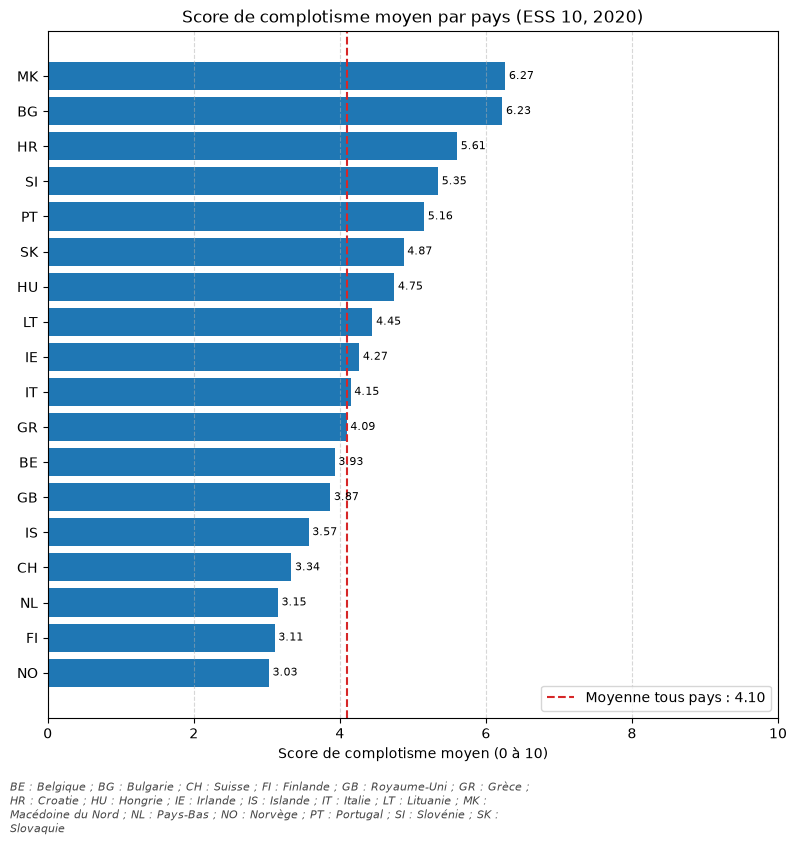

In [140]:
df_plot = df_final.dropna(subset=["score_complot", POIDS]).copy()

# Moyenne pondérée par pays
moy_pays = (
    df_plot.groupby("pays")
    .apply(lambda g: np.average(g["score_complot"], weights=g[POIDS]))
    .sort_values()
)
moy_globale = np.average(df_plot["score_complot"], weights=df_plot[POIDS])

# Légende : "BG : Bulgarie ; CH : Suisse ; ..." (ordre alphabétique des codes)
legende = " ; ".join(f"{c} : {noms_pays.get(c, c)}" for c in sorted(moy_pays.index))
legende = textwrap.fill(legende, width=95)

# Graphique
fig, ax = plt.subplots(figsize=(8, 0.35 * len(moy_pays) + 2.2))
barres = ax.barh(moy_pays.index, moy_pays.values, color="#1f77b4")
ax.axvline(moy_globale, color="#d62728", linestyle="--", linewidth=1.5,
           label=f"Moyenne tous pays : {moy_globale:.2f}")

for barre, val in zip(barres, moy_pays.values):
    ax.text(val + 0.05, barre.get_y() + barre.get_height() / 2,
            f"{val:.2f}", va="center", fontsize=8)

ax.set_xlabel("Score de complotisme moyen (0 à 10)")
ax.set_title("Score de complotisme moyen par pays (ESS 10, 2020)", fontsize=12)
ax.set_xlim(0, max(10, moy_pays.max() + 0.8))
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")

# Légende des initiales en italique, sous le graphique
fig.text(0.01, 0.01, legende, ha="left", va="bottom",
         fontsize=8, style="italic", color="#444444")

plt.tight_layout(rect=(0, 0.08, 1, 1))  # laisse de la place en bas pour la légende
plt.show()

Ce classement est quasiment l’inverse de celui de la confiance dans les institutions : les pays les plus défiants envers leurs institutions sont aussi les plus complotistes, ce qui est cohérent et conforme à la littérature et à nos hypothèses. Les pays d’Europe centrale et orientale et d’ex-Yougoslavie occupent le haut du classement, tandis que les pays nordiques et d’Europe de l’Ouest se situent en bas.
<br>
On observe une nouvelle fois que l'écart entre pays dépasse les trois points, comme pour la confiance dans les institutions. Cette absence d'homogénéité entre les pays nous encourage à introduire des effets fixes dans l=nos régressions.

Graphiques détaillant relation entre les variables (genre confiance_science en fonction du decile revenu etc..)

### 3. Approche bivariee et modelisation econometrique exploratoire

Afin de tester empiriquement notre problématique, nous examinons la relation entre l'adhésion aux thèses complotistes et ses déterminants institutionnels et structurels :

1. **Analyse graphique bivariée :**  
   Nous observons d'abord la corrélation brute entre la confiance accordée aux institutions politiques et le niveau d'adhésion aux récits du complot (`score_complot`) à l'aide d'un nuage de points et d'une droite de régression linéaire.

2. **Modélisation économétrique multivariée (WLS avec effets fixes pays) :**  
   Pour aller au-delà de la simple corrélation et isoler l'effet propre de chaque dimension, nous estimons un modèle de régression linéaire pondéré par les poids d'analyse (`poids_analyse`). L'introduction d'effets fixes pays (`C(pays)`) permet de neutraliser les spécificités institutionnelles et culturelles nationales non observées. 

Ce modèle teste conjointement l'impact :
* de la défiance institutionnelle et scientifique (`confiance_institutions`, `confiance_science`) ;
* de la radicalité politique (`radicalite_politique`) ;
* des déterminants socio-démographiques et territoriaux (`score_socioeco`, `degre_religiosite`, `zone_rurale`, `age`).


Nombre d'observations retenues : 19,897


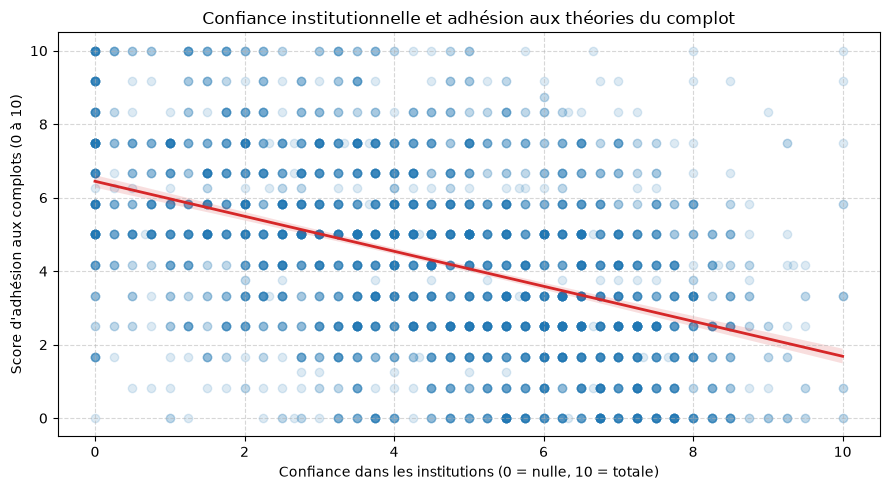


=== Coefficients de la régression linéaire (WLS) ===
                        Coefficient  Écart-type  p-value
Intercept                     7.877       0.107    0.000
confiance_institutions       -0.189       0.009    0.000
confiance_science            -0.284       0.008    0.000
radicalite_politique         -0.020       0.010    0.039
score_socioeco               -2.191       0.085    0.000
degre_religiosite             0.049       0.005    0.000
zone_rurale                   0.080       0.032    0.012
age                          -0.001       0.001    0.195

R² ajusté : 0.247


In [142]:
# 1. Sélection de l'échantillon d'estimation
variables_modele = [
    "score_complot", "confiance_institutions", "confiance_science",
    "radicalite_politique", "score_socioeco", "degre_religiosite",
    "zone_rurale", "age"
]

df_reg = df_final.dropna(subset=variables_modele + ["poids_analyse"]).copy()

print(f"Nombre d'observations retenues : {len(df_reg):,}")

# 2. Graphique : relation bivariée Confiance dans les institutions vs Score de complot
plt.figure(figsize=(9, 5))
sns.regplot(
    data=df_reg.sample(n=min(3000, len(df_reg)), random_state=42),
    x="confiance_institutions",
    y="score_complot",
    scatter_kws={"alpha": 0.15, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2}
)
plt.title("Confiance institutionnelle et adhésion aux théories du complot", fontsize=12)
plt.xlabel("Confiance dans les institutions (0 = nulle, 10 = totale)", fontsize=10)
plt.ylabel("Score d'adhésion aux complots (0 à 10)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Régression linéaire pondérée (WLS) avec effets fixes pays
formule = (
    "score_complot ~ confiance_institutions + confiance_science + "
    "radicalite_politique + score_socioeco + degre_religiosite + "
    "zone_rurale + age + C(pays)"
)

modele = smf.wls(formula=formule, data=df_reg, weights=df_reg["poids_analyse"]).fit()

# Tableau des coefficients principaux (hors indicatrices de pays)
params_cles = [p for p in modele.params.index if not p.startswith("C(pays)")]
resultats = pd.DataFrame({
    "Coefficient": modele.params[params_cles],
    "Écart-type": modele.bse[params_cles],
    "p-value": modele.pvalues[params_cles].round(4)
}).round(3)

print("\n=== Coefficients de la régression linéaire (WLS) ===")
print(resultats.to_string())
print(f"\nR² ajusté : {modele.rsquared_adj:.3f}")


#### Interprétation des résultats

* **Rupture de confiance (institutions et science) :** la relation bivariée et l'estimation multivariée confirment notre intuition centrale. Les coefficients associés à `confiance_institutions` ($-0,189$) et `confiance_science` ($-0,284$) sont postitifs et très significatifs ($p < 0,001$) : la perte de confiance dans l'expertise scientifique et les institutions représentatives constitue le moteur principal de l'adhésion aux récits du complot.
* **Barrière socio-éducative :** l'indicateur `score_socioeco` affiche un effet protecteur majeur ($-2,191$, $p < 0,001$). À niveau de défiance institutionnelle égal, disposer d'un capital économique et scolaire élevé réduit nettement la propension complotiste.
* **Facteurs culturels et territoriaux :** l'intensité religieuse (`degre_religiosite`, $+0,049$) ainsi que la résidence en milieu rural (`zone_rurale`, $+0,080$) augmentent légèrement mais significativement le score d'adhésion. 
* **Âge et radicalité :** l'âge n'apparaît pas statistiquement significatif ($p = 0,222$) une fois les autres dimensions contrôlées, montrant que le complotisme transcende les clivages générationnels.

Le modèle explique près de 25 % de la variance intra-pays ($R^2 \text{ ajusté} = 0,248$), ce qui atteste d'un bon pouvoir explicatif pour des données d'opinion en coupe transversale.


## IV. Conclusion

Ceci est une conclusion